# Tayseer Government Services — Data Visualization (Seaborn & Matplotlib)

**Course project** — SDAIA *Data Visualization and Storytelling* (Aug 2026). The dataset was provided with the course materials.

**Objective:** explore government-service KPIs across 13 regions, 4 service channels and 9 service categories (monthly data, mid-2021 to mid-2026) and identify which channels and regions lag.

**Main columns:** `month`, `region`, `channel`, `service_category`, `transactions`, `unique_users`, `digital_adoption_pct`, `avg_completion_min`, `cost_per_txn_sar`, `csat` (1–5), `sla_met_pct`, `complaints`.

**Contents:** (1–2) trends over time · (3–4) regional and category comparisons · (5–7) channel efficiency, SLA and cost vs. satisfaction · (8–9) complaints and correlations · (10) SLA by channel and category · (11–12) a standardized regional performance score.

> Run order: place `tayseer_services.csv` in `data/`, then *Restart & Run All*. Charts are saved to `figures/`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs("figures", exist_ok=True)

In [2]:
df = pd.read_csv("data/tayseer_services.csv")
df["month"] = pd.to_datetime(df["month"])

## Data overview
Quick structure and quality checks before plotting.

In [3]:
print(df.shape)
df.info()
print("\nMissing values per column:")
print(df.isna().sum())
print("\nRegions:", df["region"].nunique(), "| Channels:", df["channel"].nunique(),
      "| Service categories:", df["service_category"].nunique())
print("Period:", df["month"].min().date(), "->", df["month"].max().date())
df.head()

(28080, 12)
<class 'pandas.DataFrame'>
RangeIndex: 28080 entries, 0 to 28079
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   month                 28080 non-null  datetime64[us]
 1   region                28080 non-null  str           
 2   service_category      28080 non-null  str           
 3   channel               28080 non-null  str           
 4   transactions          28080 non-null  int64         
 5   unique_users          28080 non-null  int64         
 6   digital_adoption_pct  28080 non-null  float64       
 7   avg_completion_min    28080 non-null  float64       
 8   cost_per_txn_sar      28080 non-null  float64       
 9   csat                  28080 non-null  float64       
 10  sla_met_pct           28080 non-null  float64       
 11  complaints            28080 non-null  int64         
dtypes: datetime64[us](1), float64(5), int64(3), str(3)
memory usage: 2.6 MB



,month,region,service_category,channel,transactions,unique_users,digital_adoption_pct,avg_completion_min,cost_per_txn_sar,csat,sla_met_pct,complaints
0,2021-07-01,Al-Baha,Business & Licensing,Branch,5727,4745,33.4,117.0,51.88,3.05,80.7,10
1,2021-07-01,Al-Baha,Business & Licensing,Call Center,2575,1708,33.4,31.5,24.11,3.57,93.2,2
2,2021-07-01,Al-Baha,Business & Licensing,Mobile App,1936,721,33.4,13.7,6.26,4.13,96.2,1
3,2021-07-01,Al-Baha,Business & Licensing,Web Portal,2425,1221,33.4,19.4,8.63,3.85,94.9,3
4,2021-07-01,Al-Baha,Education & Training,Branch,7443,5923,37.0,29.4,39.00,3.55,84.4,7


In [4]:

sns.set_theme(context="notebook", style="whitegrid", font_scale=1.05)
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.titlesize"] = 15
plt.rcParams["axes.titlepad"] = 14
plt.rcParams["figure.dpi"] = 130
plt.rcParams["savefig.dpi"] = 150
plt.rcParams["savefig.bbox"] = "tight"

channel_colors = {
    "Branch": "#8d99ae",
    "Call Center": "#f4a259",
    "Mobile App": "#2a9d8f",
    "Web Portal": "#4361ee",
}
region_palette = "flare"
category_palette = "crest"

## 1. Transactions over time, by channel

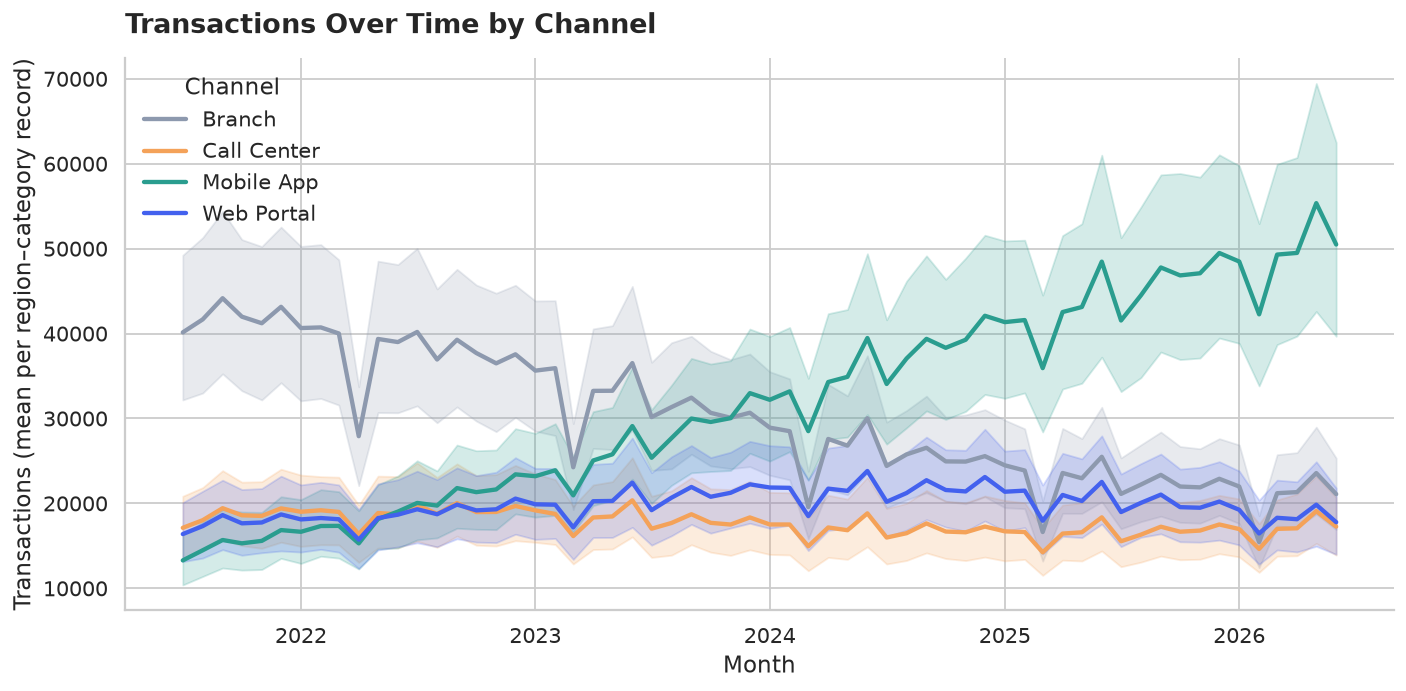

In [5]:
plt.figure(figsize=(11, 5.5))
sns.lineplot(data=df, x="month", y="transactions", hue="channel",
             palette=channel_colors, linewidth=2.4)
plt.title("Transactions Over Time by Channel", loc="left")
plt.xlabel("Month")
plt.ylabel("Transactions (mean per region–category record)")
plt.legend(title="Channel", frameon=False, loc="upper left")
sns.despine()
plt.tight_layout()
plt.savefig("figures/01_transactions_over_time.png")
plt.show()

**Observations.** Branch transactions fall from roughly 41k to 21k per record, while Mobile App grows from roughly 13k to 50k and overtakes Branch around the start of 2024. Call Center and Web Portal stay broadly flat (about 17–22k). Every year shows a dip in the first months, which suggests seasonality. *Note: the line is the mean per region–category record; shaded bands are 95% confidence intervals.*

## 2. Digital adoption percentage over time, by region

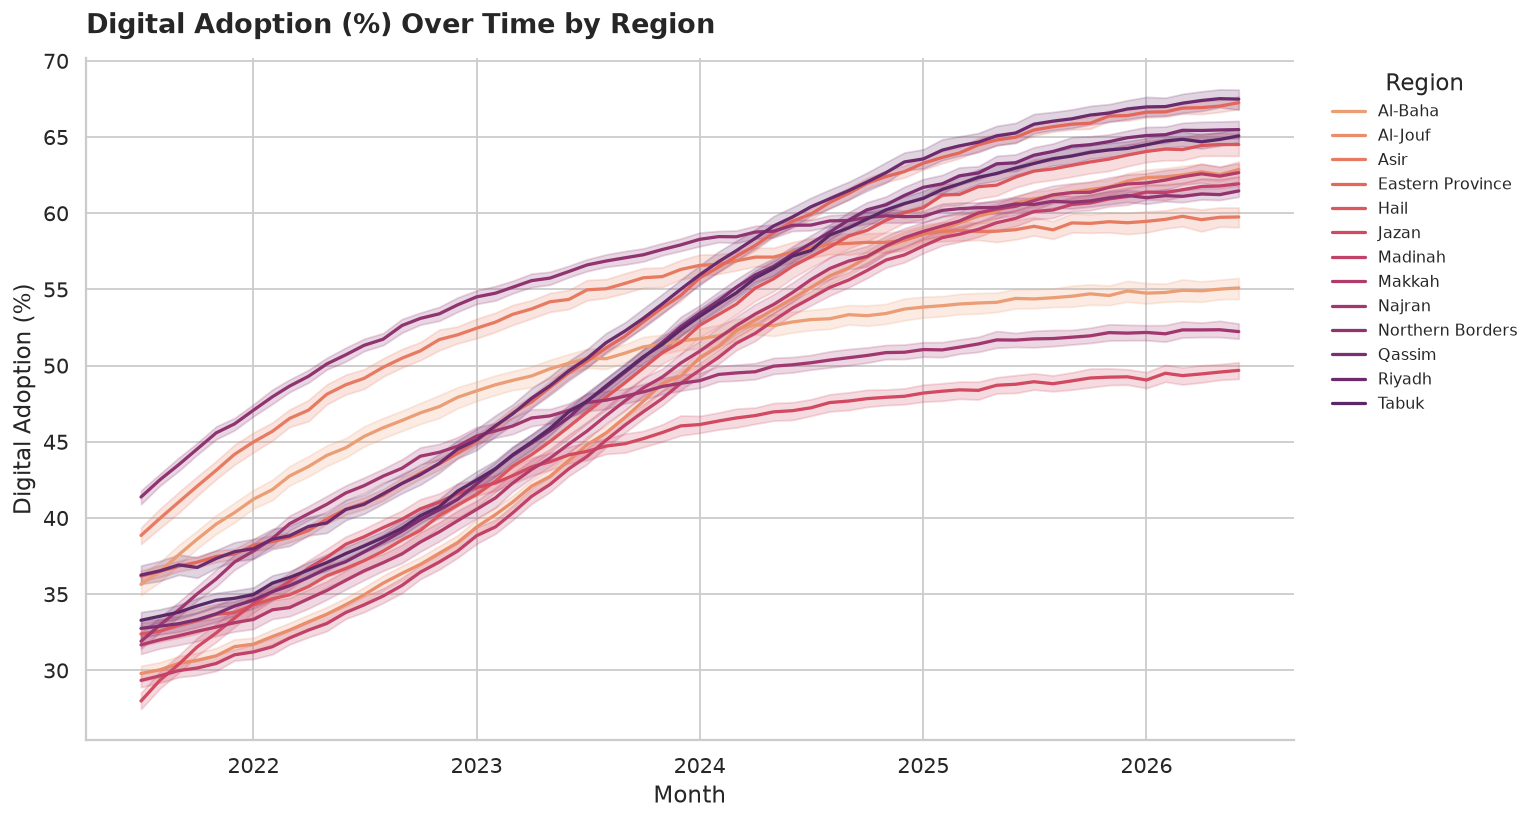

In [6]:
plt.figure(figsize=(12, 6.5))
sns.lineplot(data=df, x="month", y="digital_adoption_pct", hue="region",
             palette=region_palette, linewidth=1.8)
plt.title("Digital Adoption (%) Over Time by Region", loc="left")
plt.xlabel("Month")
plt.ylabel("Digital Adoption (%)")
plt.legend(title="Region", bbox_to_anchor=(1.02, 1), loc="upper left",
           frameon=False, fontsize=9)
sns.despine()
plt.tight_layout()
plt.savefig("figures/02_digital_adoption_by_region.png")
plt.show()

**Observations.** Digital adoption rises in every region (from roughly 28–41% in mid-2021 to roughly 50–67% in mid-2026), growth flattens in 2025–2026, and the gap between the leading and lagging regions widens (about 13 to 18 points).

## 3. Total transactions by region

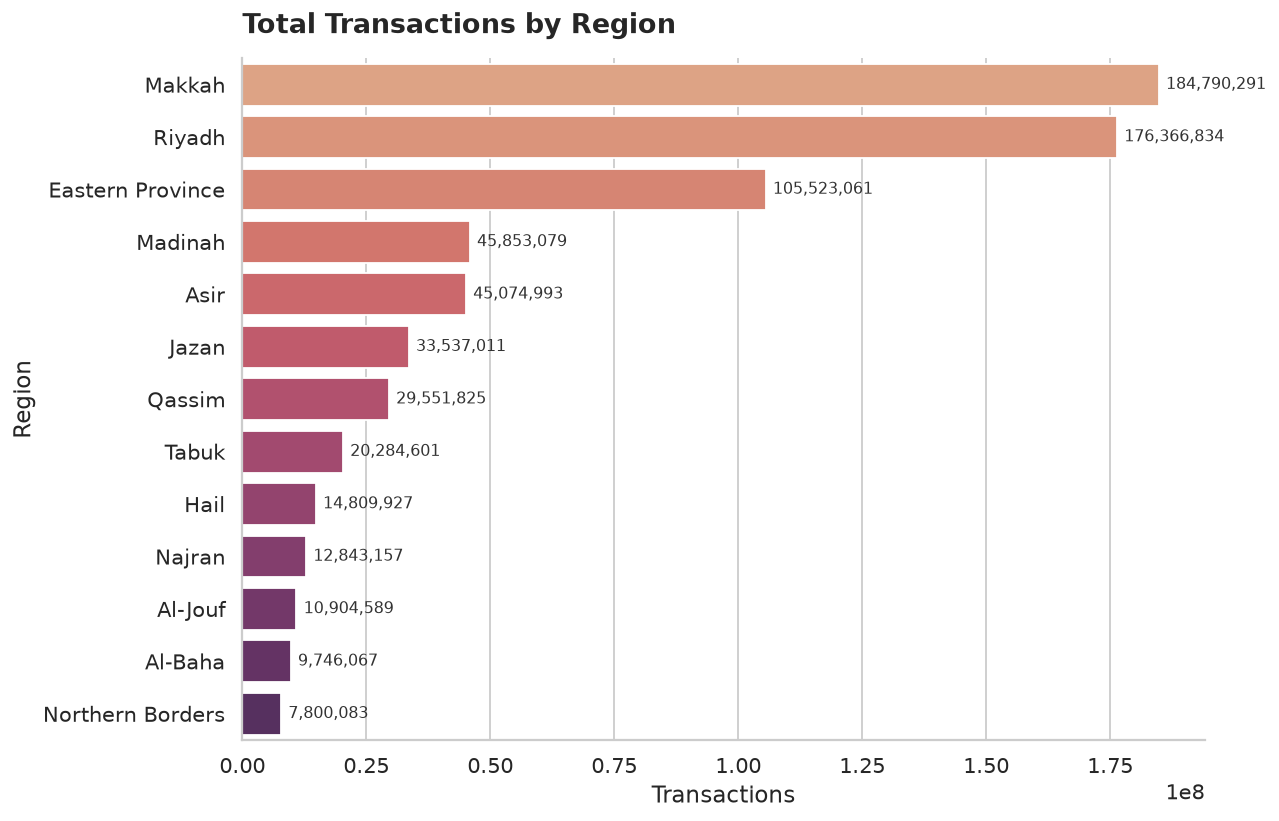

In [7]:
plt.figure(figsize=(10, 6.5))
region_order = df.groupby("region")["transactions"].sum().sort_values(ascending=False).index
ax = sns.barplot(data=df, x="transactions", y="region", hue="region",
                  estimator=sum, errorbar=None, palette=region_palette,
                  order=region_order, hue_order=region_order, legend=False)
plt.title("Total Transactions by Region", loc="left")
plt.xlabel("Transactions")
plt.ylabel("Region")
for bars in ax.containers:
    ax.bar_label(bars, fmt="{:,.0f}", padding=4, fontsize=9, color="#333333")
sns.despine()
plt.tight_layout()
plt.savefig("figures/03_total_transactions_by_region.png")
plt.show()

**Observations.** Volume is highly concentrated: Makkah (184.8M), Riyadh (176.4M) and Eastern Province (105.5M) together account for about two-thirds of all transactions, while Northern Borders (7.8M) and Al-Baha (9.7M) are the smallest.

## 4. Average CSAT by service category

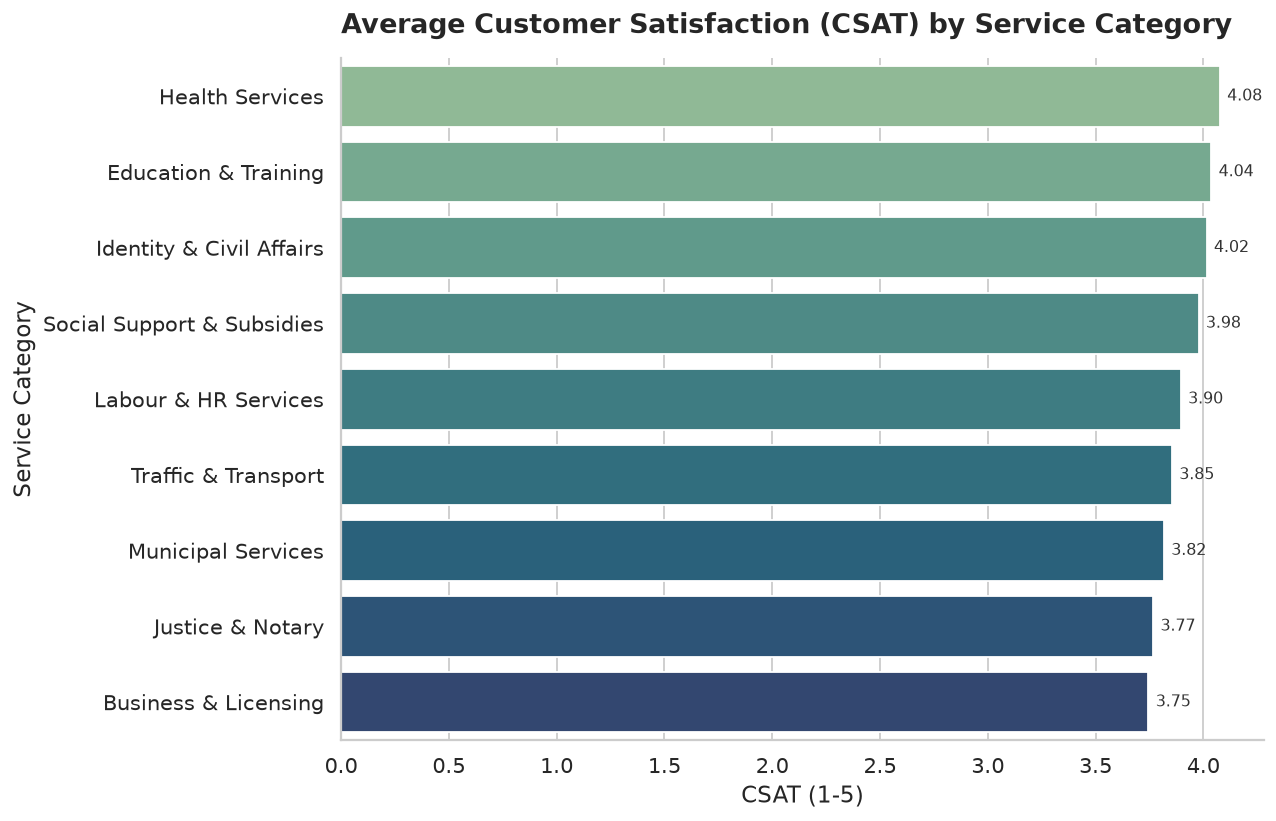

In [8]:
plt.figure(figsize=(10, 6.5))
category_order = df.groupby("service_category")["csat"].mean().sort_values(ascending=False).index
ax = sns.barplot(data=df, x="csat", y="service_category", hue="service_category",
                  errorbar=None, palette=category_palette,
                  order=category_order, hue_order=category_order, legend=False)
plt.title("Average Customer Satisfaction (CSAT) by Service Category", loc="left")
plt.xlabel("CSAT (1-5)")
plt.ylabel("Service Category")
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f", padding=4, fontsize=9, color="#333333")
sns.despine()
plt.tight_layout()
plt.savefig("figures/04_csat_by_service_category.png")
plt.show()

**Observations.** Satisfaction is high and fairly uniform across categories (3.75–4.08 out of 5). Health Services leads (4.08) and Business & Licensing is lowest (3.75). The bars start at zero, so the differences look small; the spread is about 0.33 points.

## 5. Average completion time by channel (boxplot)

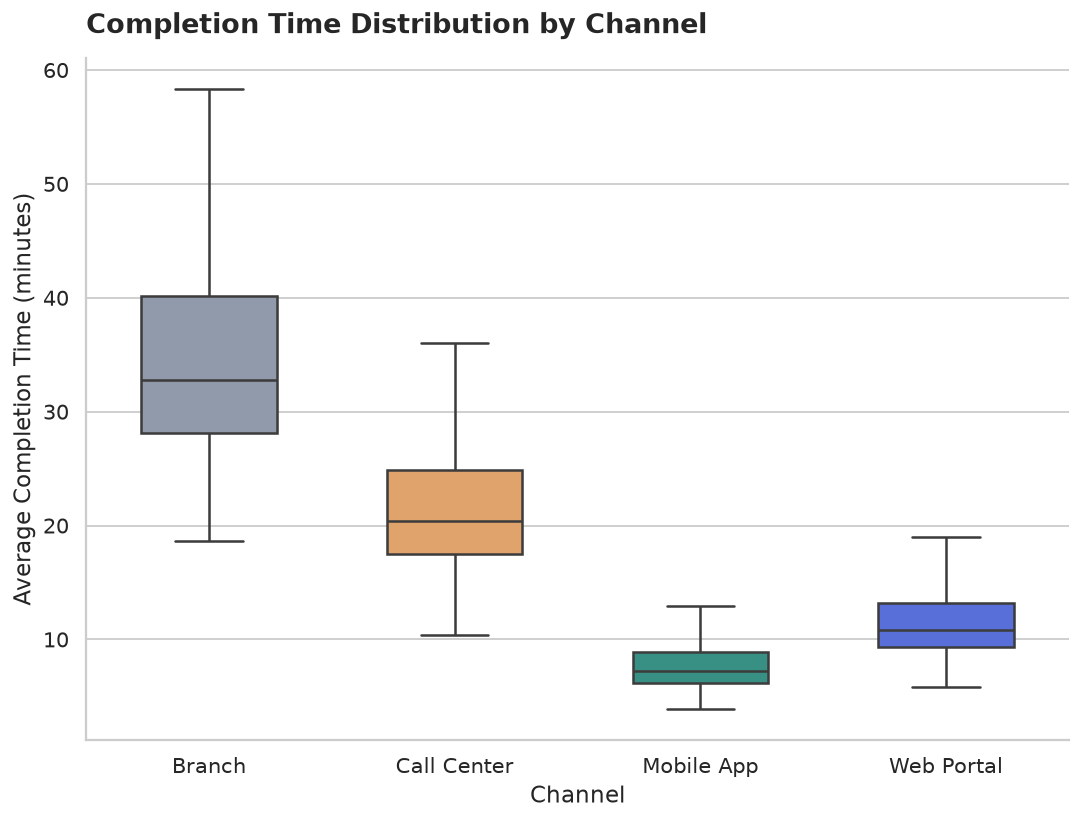

In [9]:
plt.figure(figsize=(8.5, 6.5))
sns.boxplot(data=df, x="channel", y="avg_completion_min", hue="channel",
            palette=channel_colors, width=0.55, linewidth=1.4,
            showfliers=False, legend=False)
plt.title("Completion Time Distribution by Channel", loc="left")
plt.xlabel("Channel")
plt.ylabel("Average Completion Time (minutes)")
sns.despine()
plt.tight_layout()
plt.savefig("figures/05_completion_time_by_channel.png")
plt.show()

**Observations.** Median completion time ranks Mobile App (≈7 min) < Web Portal (≈11) < Call Center (≈20) < Branch (≈33). Branch also has by far the widest spread (≈18–58 min). Outliers are hidden (`showfliers=False`) to keep the comparison readable.

## 6. Relationship between completion time and SLA compliance

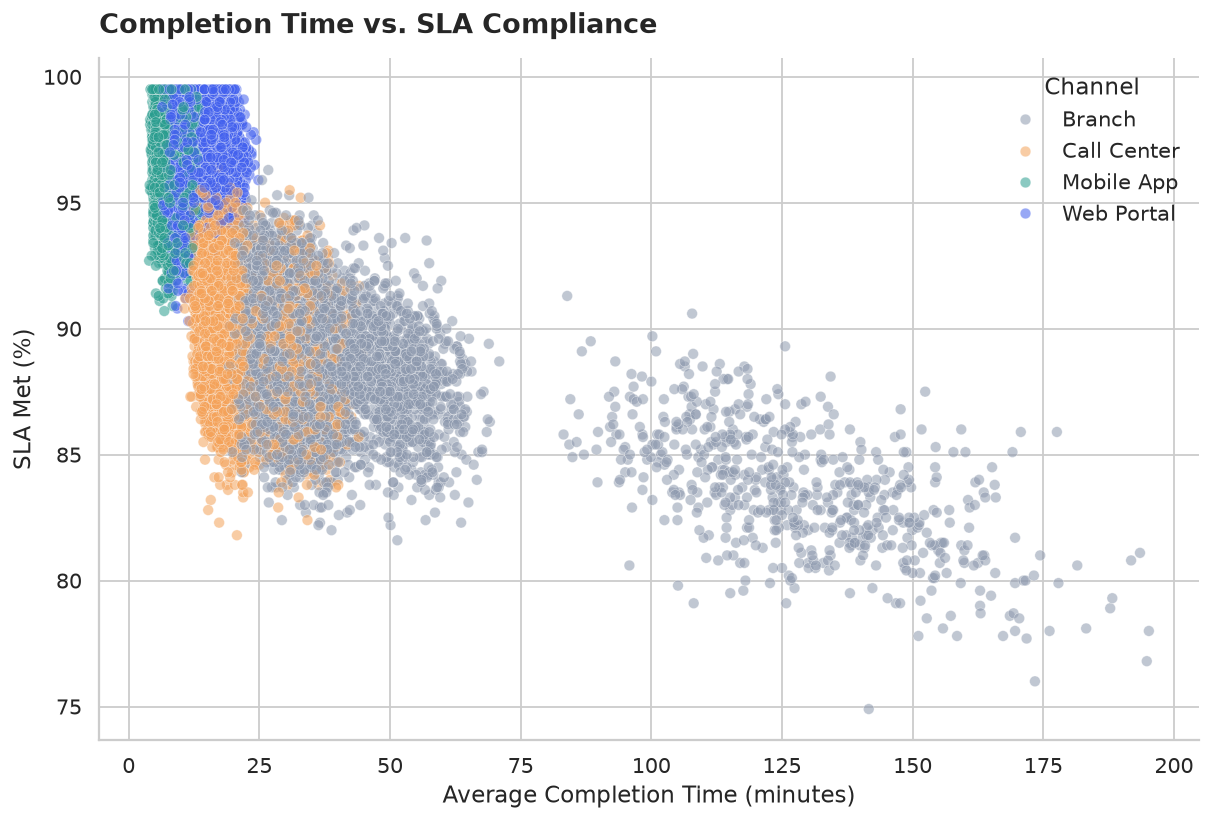

In [10]:
plt.figure(figsize=(9.5, 6.5))
sns.scatterplot(data=df, x="avg_completion_min", y="sla_met_pct", hue="channel",
                 palette=channel_colors, alpha=0.55, s=35, edgecolor="white", linewidth=0.3)
plt.title("Completion Time vs. SLA Compliance", loc="left")
plt.xlabel("Average Completion Time (minutes)")
plt.ylabel("SLA Met (%)")
plt.legend(title="Channel", frameon=False)
sns.despine()
plt.tight_layout()
plt.savefig("figures/06_completion_time_vs_sla.png")
plt.show()

**Observations.** Longer completion times go with lower SLA compliance (pooled correlation ≈ −0.67, see the heatmap in section 9). The scatter is clustered by channel, so part of this relationship reflects channel differences.

## 7. Relationship between cost per transaction and CSAT

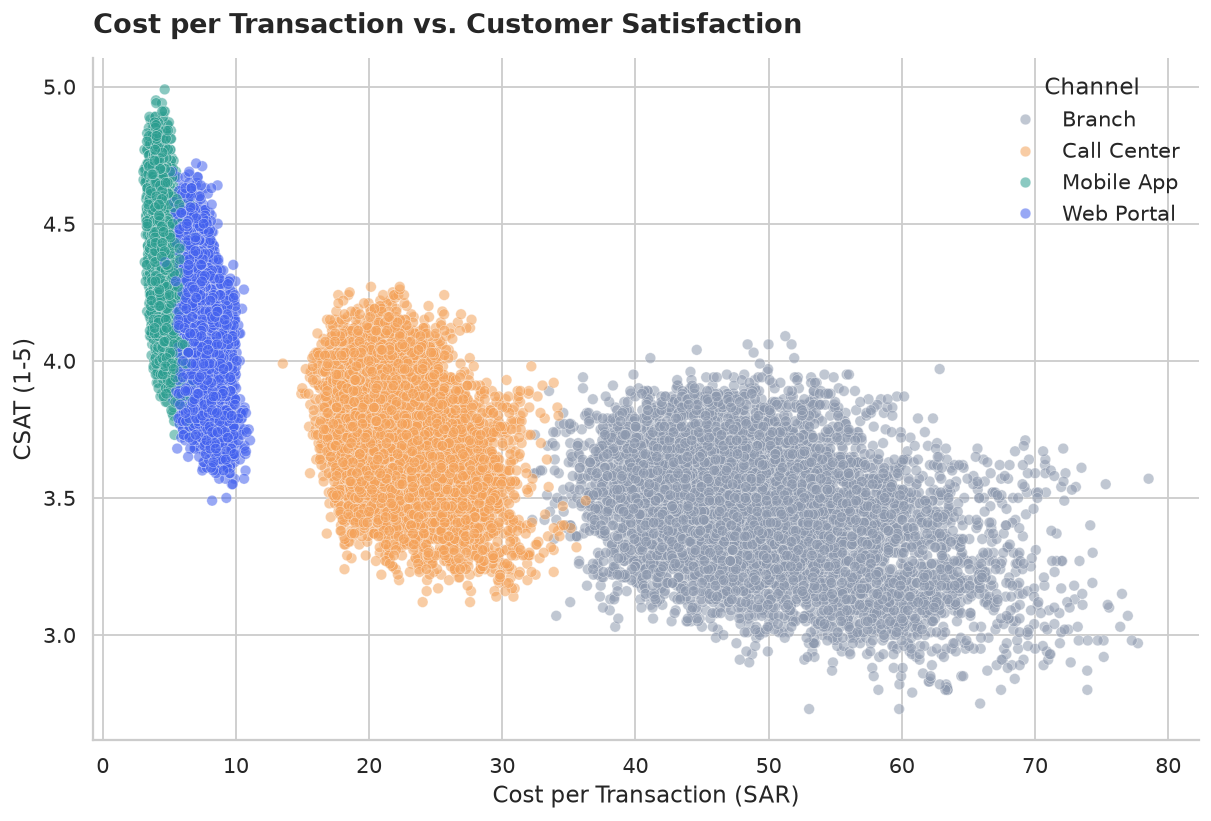

In [11]:
plt.figure(figsize=(9.5, 6.5))
sns.scatterplot(data=df, x="cost_per_txn_sar", y="csat", hue="channel",
                 palette=channel_colors, alpha=0.55, s=35, edgecolor="white", linewidth=0.3)
plt.title("Cost per Transaction vs. Customer Satisfaction", loc="left")
plt.xlabel("Cost per Transaction (SAR)")
plt.ylabel("CSAT (1-5)")
plt.legend(title="Channel", frameon=False)
sns.despine()
plt.tight_layout()
plt.savefig("figures/07_cost_vs_csat.png")
plt.show()

**Observations.** Higher cost per transaction goes with lower satisfaction. The pooled correlation is strong (about −0.82), but within each channel it is only moderate (−0.37 to −0.47, see the table below), so much of the pooled relationship comes from differences between channels.

In [12]:
within_channel = (df.groupby("channel")[["cost_per_txn_sar", "csat"]].corr()
                 .xs("cost_per_txn_sar", level=1)["csat"]
                 .round(2)
                 .rename("corr(cost, CSAT) within channel"))
within_channel

channel
Branch        -0.37
Call Center   -0.38
Mobile App    -0.47
Web Portal    -0.43
Name: corr(cost, CSAT) within channel, dtype: float64

## 8. Complaints by service category

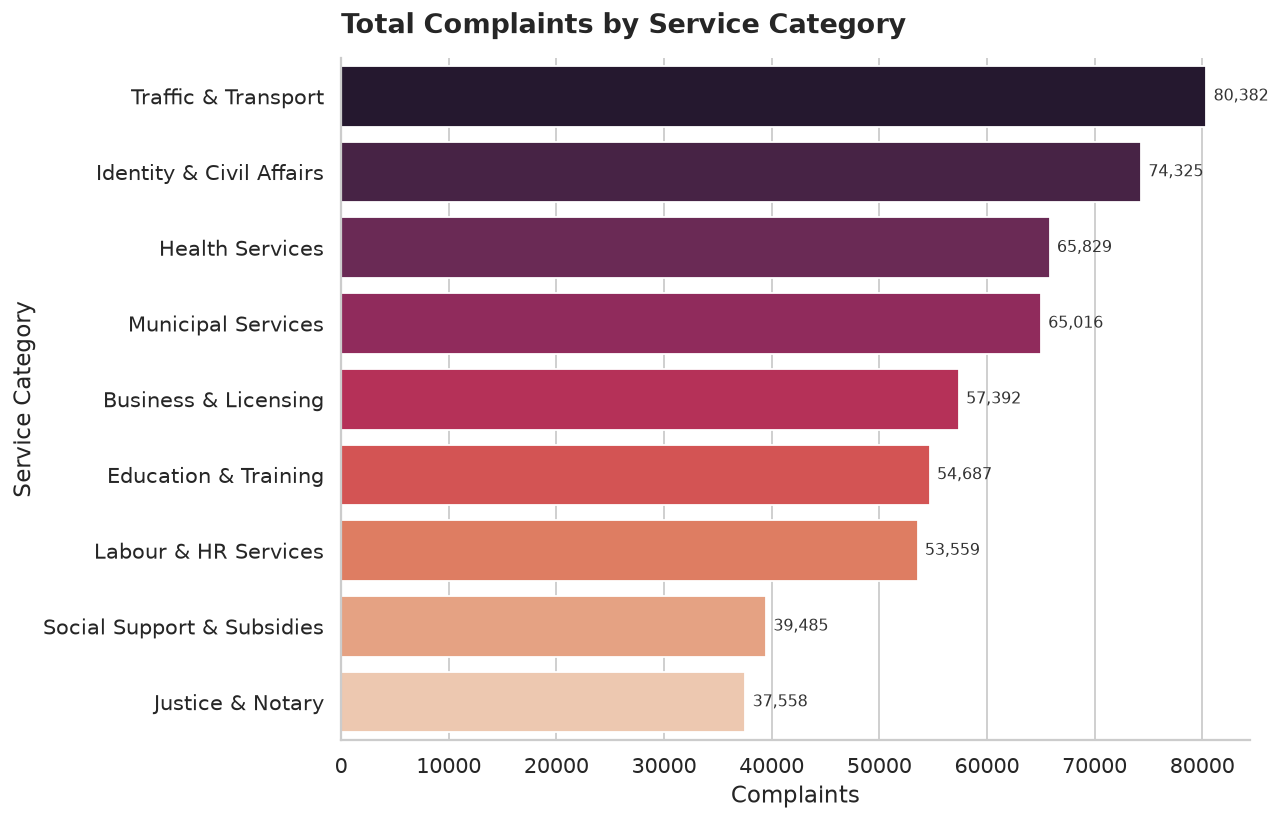

In [13]:
plt.figure(figsize=(10, 6.5))
complaints_order = df.groupby("service_category")["complaints"].sum().sort_values(ascending=False).index
ax = sns.barplot(data=df, x="complaints", y="service_category", hue="service_category",
                  estimator=sum, errorbar=None, palette="rocket",
                  order=complaints_order, hue_order=complaints_order, legend=False)
plt.title("Total Complaints by Service Category", loc="left")
plt.xlabel("Complaints")
plt.ylabel("Service Category")
for bars in ax.containers:
    ax.bar_label(bars, fmt="{:,.0f}", padding=4, fontsize=9, color="#333333")
sns.despine()
plt.tight_layout()
plt.savefig("figures/08_complaints_by_service_category.png")
plt.show()

**Observations.** Traffic & Transport has the most complaints (80,382) and Justice & Notary the fewest (37,558), but raw counts mostly track volume (correlation with `unique_users` about 0.93). Per 100 transactions the ranking changes (table below): Business & Licensing (0.093) and Justice & Notary (0.091) are highest and Health Services (0.063) is lowest. Business & Licensing and Justice & Notary also have the lowest satisfaction scores (3.75 and 3.77).

In [14]:
sums = df.groupby("service_category")[["complaints", "transactions"]].sum()
complaint_rate_by_category = ((sums["complaints"] / sums["transactions"] * 100)
                              .sort_values(ascending=False)
                              .round(3)
                              .rename("complaints per 100 transactions"))
complaint_rate_by_category

service_category
Business & Licensing          0.093
Justice & Notary              0.091
Municipal Services            0.086
Traffic & Transport           0.082
Labour & HR Services          0.078
Social Support & Subsidies    0.072
Identity & Civil Affairs      0.068
Education & Training          0.066
Health Services               0.063
Name: complaints per 100 transactions, dtype: float64

## 9. Correlation heatmap between numeric columns

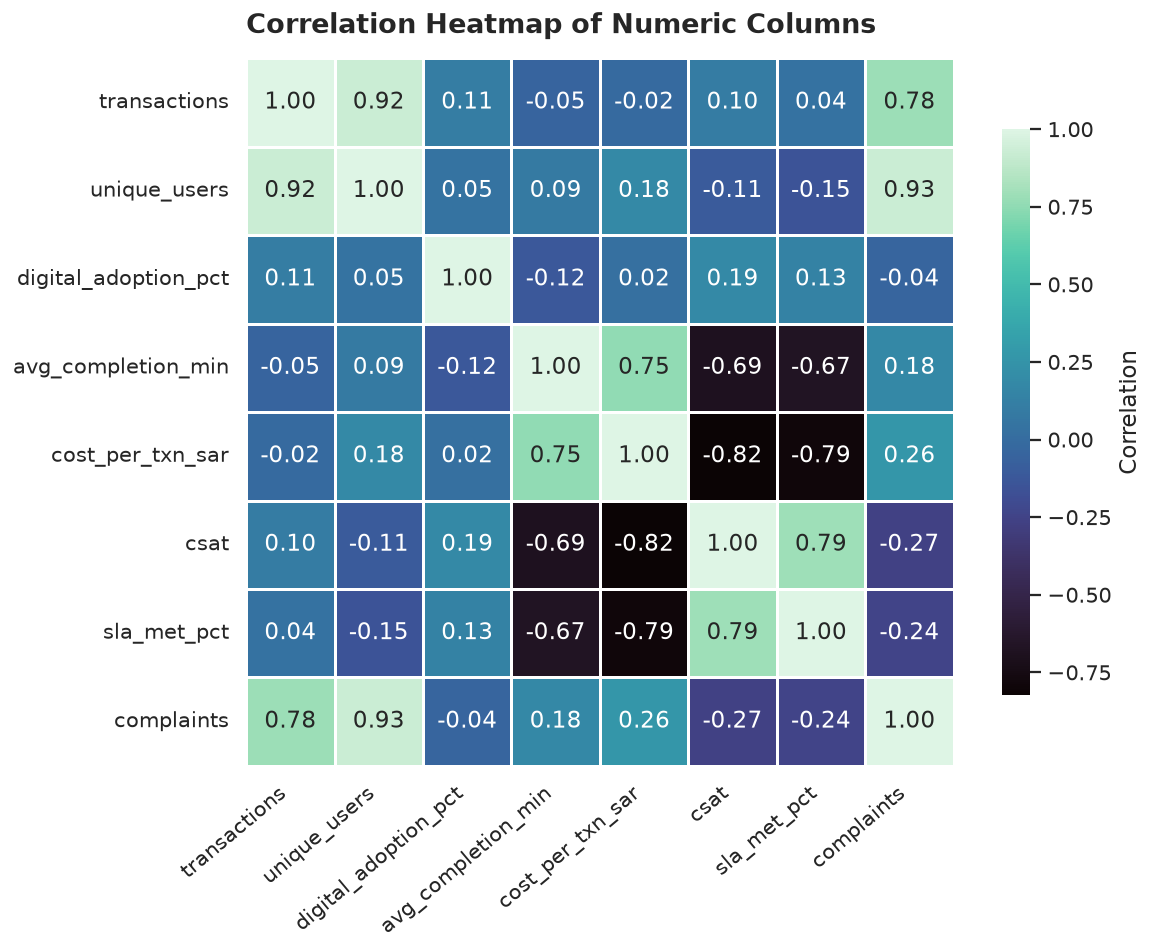

In [15]:
plt.figure(figsize=(9.5, 7.5))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="mako",
            linewidths=0.6, linecolor="white", square=True,
            cbar_kws={"label": "Correlation", "shrink": 0.8})
plt.title("Correlation Heatmap of Numeric Columns", loc="left")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.savefig("figures/09_correlation_heatmap.png")
plt.show()

**Observations.** Complaints scale with volume (≈ 0.93 with `unique_users`, ≈ 0.78 with `transactions`). Cost, completion time, CSAT and SLA form a tight cluster: cost vs. CSAT ≈ −0.82, cost vs. SLA ≈ −0.79, completion time vs. CSAT ≈ −0.69, cost vs. completion time ≈ +0.75. Digital adoption shows only weak correlations (|r| ≤ 0.19). *Correlation does not imply causation.*

## 10. Average SLA compliance by channel and service category

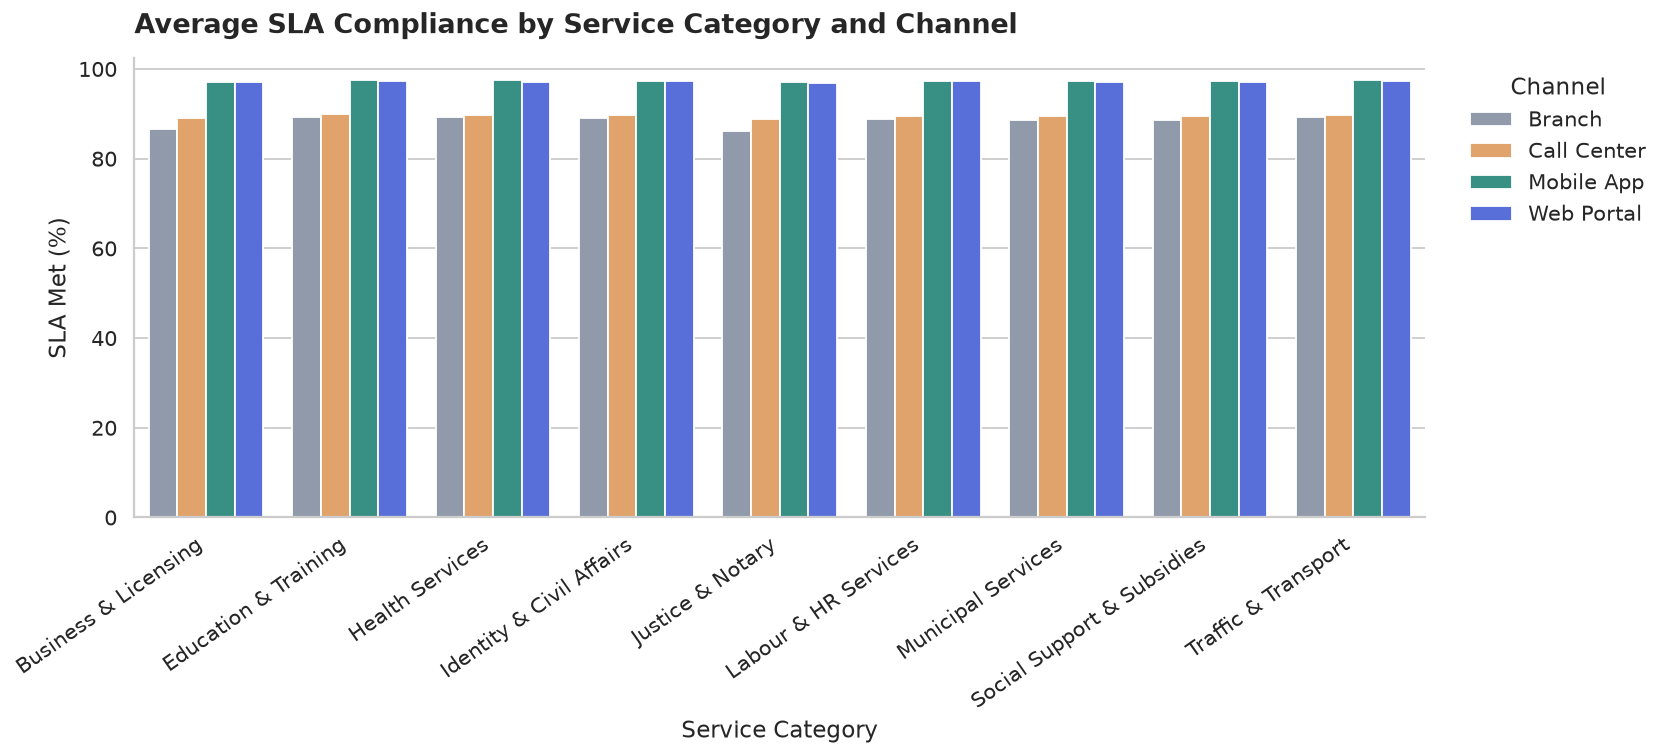

In [16]:
plt.figure(figsize=(13, 6))
sns.barplot(data=df, x="service_category", y="sla_met_pct", hue="channel",
            palette=channel_colors, errorbar=None)
plt.title("Average SLA Compliance by Service Category and Channel", loc="left")
plt.xlabel("Service Category")
plt.ylabel("SLA Met (%)")
plt.xticks(rotation=35, ha="right")
plt.legend(title="Channel", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
sns.despine()
plt.tight_layout()
plt.savefig("figures/10_sla_by_category_and_channel.png")
plt.show()

**Observations.** Mobile App and Web Portal reach about 97% SLA compliance in every category, versus roughly 86–90% for Branch and Call Center. The channel matters far more than the service category. The y-axis starts at zero, which compresses the visible gap.

## 11. Regional performance profile (standardized) — spotting struggling regions

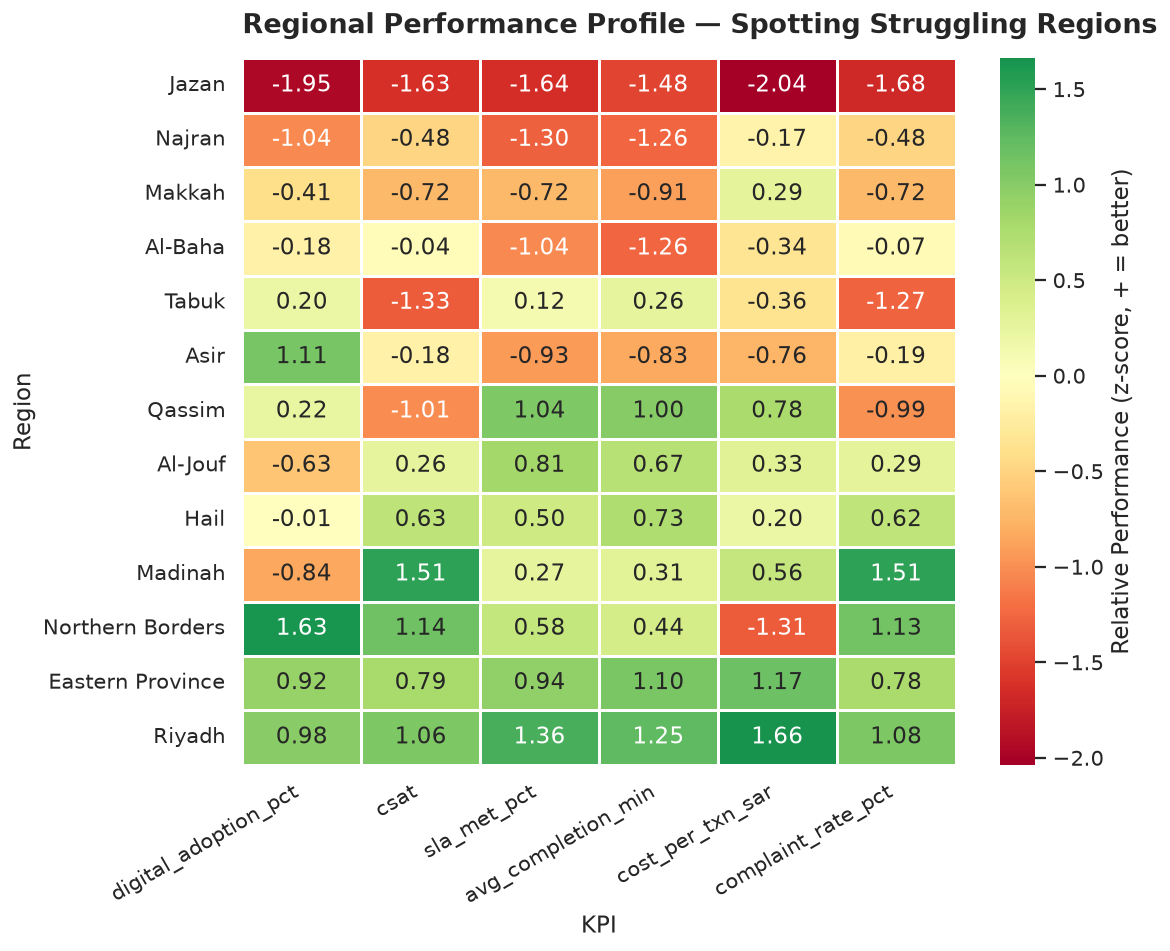

In [17]:
df["complaint_rate_pct"] = df["complaints"] / df["transactions"] * 100

better_high = ["digital_adoption_pct", "csat", "sla_met_pct"]
better_low = ["avg_completion_min", "cost_per_txn_sar", "complaint_rate_pct"]

regional_avg = df.groupby("region")[better_high + better_low].mean()
regional_z = (regional_avg - regional_avg.mean()) / regional_avg.std()
regional_z[better_low] = -regional_z[better_low]
regional_z = regional_z.loc[regional_z.mean(axis=1).sort_values(ascending=True).index]

plt.figure(figsize=(9, 7.5))
sns.heatmap(regional_z, annot=True, fmt=".2f", cmap="RdYlGn", center=0,
            linewidths=0.6, linecolor="white",
            cbar_kws={"label": "Relative Performance (z-score, + = better)"})
plt.title("Regional Performance Profile — Spotting Struggling Regions", loc="left")
plt.xlabel("KPI")
plt.ylabel("Region")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("figures/11_regional_performance_profile.png")
plt.show()

**Observations.** The heatmap shows which KPIs drag each region down; regions at the top are the weakest overall.

## 12. Overall regional performance score — struggling vs. leading regions

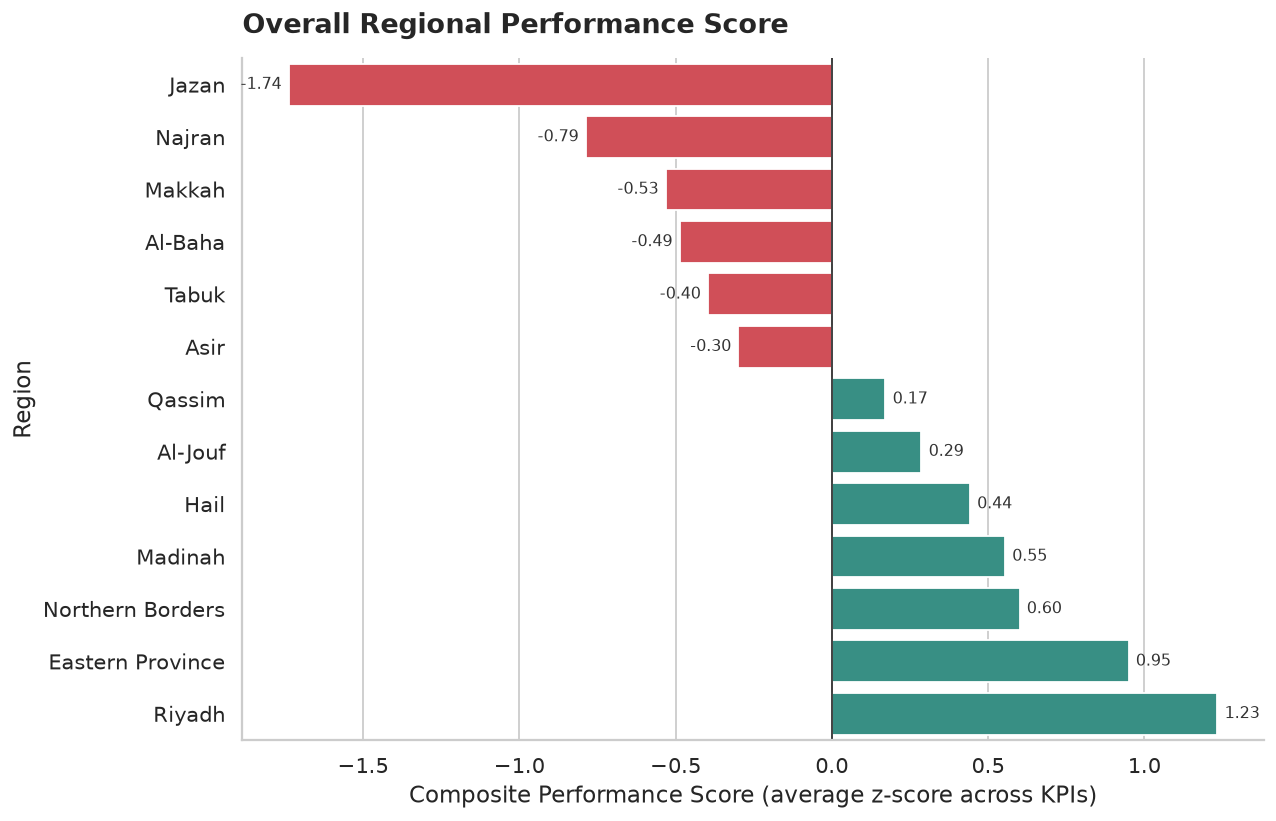

In [18]:
regional_score = regional_z.mean(axis=1).sort_values()

plt.figure(figsize=(10, 6.5))
bar_colors = ["#e63946" if v < 0 else "#2a9d8f" for v in regional_score.values]
ax = sns.barplot(x=regional_score.values, y=regional_score.index,
                  hue=regional_score.index, palette=bar_colors, legend=False)
plt.axvline(0, color="#333333", linewidth=1)
plt.title("Overall Regional Performance Score", loc="left")
plt.xlabel("Composite Performance Score (average z-score across KPIs)")
plt.ylabel("Region")
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f", padding=4, fontsize=9, color="#333333")
sns.despine()
plt.tight_layout()
plt.savefig("figures/12_regional_performance_score.png")
plt.show()

**Observations.** Six regions score below the average: Jazan (−1.74), Najran (−0.79), Makkah (−0.53), Al-Baha (−0.49), Tabuk (−0.40) and Asir (−0.30). Riyadh (+1.23) and Eastern Province (+0.95) lead. Makkah has the highest transaction volume yet scores below average, so scale does not imply performance.

## Key findings
- **Channel shift:** Mobile App has overtaken Branch as the highest-volume channel (around the start of 2024) and is also the fastest (median about 7 min vs. about 33 for Branch).
- **Channel drives service quality:** digital channels meet SLA about 97% of the time versus 88–90% for Branch and Call Center.
- **Cost, speed and satisfaction move together, partly through channel mix:** across all records, cost and completion time correlate strongly and negatively with CSAT and SLA (about −0.7 to −0.8), but within a single channel the cost–CSAT link is only moderate (−0.37 to −0.47).
- **Complaints:** by rate, Business & Licensing and Justice & Notary are highest (about 0.09 per 100 transactions), consistent with their lower satisfaction; raw complaint counts are dominated by volume.
- **Regions:** Jazan is the weakest region on the composite score (−1.74); Riyadh (+1.23) and Eastern Province (+0.95) lead. Makkah is the largest region by volume but scores below average.
- **Concentration:** three regions generate about two-thirds of all transactions (66.9%).
## Limitations
- The dataset comes from the course materials and is likely synthetic, so these findings illustrate the analysis, not real service performance.
- The composite score is relative (z-scores across regions with equal KPI weights), so about half of the regions fall below zero by construction. It ranks regions; it is not an absolute quality measure.
- Pooled correlations can be driven by channel differences, and correlation does not imply causation.